# Seasonal-Naive Forecasting Baseline

## Purpose

This notebook implements the frozen seasonal-naive forecasting baseline for the SA1 and NSW1 AEMO electricity-demand datasets.

The project data have been standardised to 30-minute intervals. Therefore, each day contains 48 observations. For every time point \(t\), the seasonal-naive forecast uses the actual electricity demand observed 48 intervals earlier:

$$
\hat{y}_t = y_{t-48}
$$

The forecasting rule and seasonal lag are fixed before evaluation and are not changed during the test stream. Forecasts are generated chronologically using only information available before each prediction, so future information is not used.

The baseline will be evaluated on the fixed test stream using:

- overall mean absolute error (MAE);
- 7-day rolling MAE using 336 observations;
- actual-demand versus forecast plots;
- degradation curves for SA1 and NSW1.

In [1]:
import sys
import pandas as pd
import matplotlib

print("Python executable:", sys.executable)
print("pandas version:", pd.__version__)
print("matplotlib version:", matplotlib.__version__)

Python executable: d:\University\Capstone\Detecting-and-Adapting-to-Concept-Drift-in-Time-Series-Forecasting\.venv\Scripts\python.exe
pandas version: 3.0.5
matplotlib version: 3.11.1


In [2]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt


current_directory = Path.cwd()

if (current_directory / "src").exists():
    project_root = current_directory
elif (current_directory.parent / "src").exists():
    project_root = current_directory.parent
else:
    raise FileNotFoundError(
        "Could not locate the project root containing the src folder."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import load_and_split_aemo

data_path = project_root / "data" / "raw"

print("Current directory:", current_directory)
print("Project root:", project_root)
print("Raw data path:", data_path)
print("Raw data path exists:", data_path.exists())

Matplotlib is building the font cache; this may take a moment.


Current directory: d:\University\Capstone\Detecting-and-Adapting-to-Concept-Drift-in-Time-Series-Forecasting\notebooks
Project root: d:\University\Capstone\Detecting-and-Adapting-to-Concept-Drift-in-Time-Series-Forecasting
Raw data path: d:\University\Capstone\Detecting-and-Adapting-to-Concept-Drift-in-Time-Series-Forecasting\data\raw
Raw data path exists: True


In [3]:
sa1_data, sa1_train, sa1_calibration, sa1_test = (
    load_and_split_aemo(
        region="SA1",
        data_path=data_path
    )
)

nsw1_data, nsw1_train, nsw1_calibration, nsw1_test = (
    load_and_split_aemo(
        region="NSW1",
        data_path=data_path
    )
)

print("SA1 loaded successfully.")
print("Full:", len(sa1_data))
print("Train:", len(sa1_train))
print("Calibration:", len(sa1_calibration))
print("Test:", len(sa1_test))

print()

print("NSW1 loaded successfully.")
print("Full:", len(nsw1_data))
print("Train:", len(nsw1_train))
print("Calibration:", len(nsw1_calibration))
print("Test:", len(nsw1_test))

SA1 loaded successfully.
Full: 105168
Train: 35039
Calibration: 2880
Test: 67249

NSW1 loaded successfully.
Full: 105168
Train: 35039
Calibration: 2880
Test: 67249


In [4]:
print("SA1 columns:", sa1_data.columns.tolist())
print(
    "SA1 date range:",
    sa1_data["SETTLEMENTDATE"].min(),
    "to",
    sa1_data["SETTLEMENTDATE"].max()
)

print()

print("NSW1 columns:", nsw1_data.columns.tolist())
print(
    "NSW1 date range:",
    nsw1_data["SETTLEMENTDATE"].min(),
    "to",
    nsw1_data["SETTLEMENTDATE"].max()
)

print("\nFirst five SA1 observations:")
display(sa1_data.head())

print("First five NSW1 observations:")
display(nsw1_data.head())

SA1 columns: ['SETTLEMENTDATE', 'TOTALDEMAND']
SA1 date range: 2018-01-01 00:30:00 to 2024-01-01 00:00:00

NSW1 columns: ['SETTLEMENTDATE', 'TOTALDEMAND']
NSW1 date range: 2018-01-01 00:30:00 to 2024-01-01 00:00:00

First five SA1 observations:


,SETTLEMENTDATE,TOTALDEMAND
0,2018-01-01 00:30:00,1289.10
1,2018-01-01 01:00:00,1242.28
2,2018-01-01 01:30:00,1156.19
3,2018-01-01 02:00:00,1112.46
4,2018-01-01 02:30:00,1094.20


First five NSW1 observations:


,SETTLEMENTDATE,TOTALDEMAND
0,2018-01-01 00:30:00,6912.25
1,2018-01-01 01:00:00,6745.63
2,2018-01-01 01:30:00,6466.06
3,2018-01-01 02:00:00,6279.80
4,2018-01-01 02:30:00,6177.31


In [5]:
def validate_aemo_data(data, region_name):
    required_columns = {
        "SETTLEMENTDATE",
        "TOTALDEMAND"
    }

    missing_columns = required_columns - set(data.columns)

    if missing_columns:
        raise ValueError(
            f"{region_name} is missing columns: {missing_columns}"
        )

    if not data["SETTLEMENTDATE"].is_monotonic_increasing:
        raise ValueError(
            f"{region_name} timestamps are not in chronological order."
        )

    if data["SETTLEMENTDATE"].duplicated().any():
        raise ValueError(
            f"{region_name} contains duplicated timestamps."
        )

    if data["TOTALDEMAND"].isna().any():
        raise ValueError(
            f"{region_name} contains missing demand values."
        )

    time_differences = (
        data["SETTLEMENTDATE"]
        .diff()
        .dropna()
    )

    if not (
        time_differences == pd.Timedelta(minutes=30)
    ).all():
        raise ValueError(
            f"{region_name} does not have a consistent 30-minute frequency."
        )

    print(f"{region_name} validation passed.")


validate_aemo_data(sa1_data, "SA1")
validate_aemo_data(nsw1_data, "NSW1")

timestamps_match = (
    sa1_data["SETTLEMENTDATE"]
    .reset_index(drop=True)
    .equals(
        nsw1_data["SETTLEMENTDATE"]
        .reset_index(drop=True)
    )
)

print("SA1 and NSW1 timestamps match:", timestamps_match)

SA1 validation passed.
NSW1 validation passed.
SA1 and NSW1 timestamps match: True


## Seasonal-Naive Forecasting Method

The seasonal-naive baseline does not require conventional model training or parameter fitting. Its forecasting rule is fixed before the test period:

> Forecast the current demand using the actual demand observed 48 half-hourly intervals earlier.

The seasonal lag remains fixed at 48 throughout the experiment. The model is not retrained or adjusted using test-period performance.

Forecast lags are first constructed from the complete chronological series and are then matched to the fixed test stream. This allows the first test observation to use demand already observed during the preceding calibration period.

At every prediction time $t$, the model uses only $y_{t-48}$, which is historical information already available at that time. It does not use future observations.

In [6]:
def run_seasonal_naive(
    full_data,
    test_data,
    season_length=48,
    rolling_days=7
):
    forecast_data = full_data[
        ["SETTLEMENTDATE", "TOTALDEMAND"]
    ].copy()

    forecast_data["prediction"] = (
        forecast_data["TOTALDEMAND"]
        .shift(season_length)
    )

    results = test_data[
        ["SETTLEMENTDATE", "TOTALDEMAND"]
    ].merge(
        forecast_data[
            ["SETTLEMENTDATE", "prediction"]
        ],
        on="SETTLEMENTDATE",
        how="left",
        validate="one_to_one"
    )

    if results["prediction"].isna().any():
        raise ValueError(
            "Missing seasonal-naive predictions were found "
            "in the test stream."
        )

    results["error"] = (
        results["TOTALDEMAND"]
        - results["prediction"]
    )

    results["absolute_error"] = (
        results["error"].abs()
    )

    rolling_window = (
        season_length * rolling_days
    )

    results["rolling_mae_7d"] = (
        results["absolute_error"]
        .rolling(
            window=rolling_window,
            min_periods=rolling_window
        )
        .mean()
    )

    overall_mae = (
        results["absolute_error"].mean()
    )

    return results, overall_mae

In [7]:
sa1_results, sa1_mae = run_seasonal_naive(
    full_data=sa1_data,
    test_data=sa1_test
)

print("SA1 result observations:", len(sa1_results))
print(
    "SA1 missing predictions:",
    sa1_results["prediction"].isna().sum()
)
print(
    f"SA1 seasonal-naive overall MAE: "
    f"{sa1_mae:.2f} MW"
)

display(sa1_results.head())

SA1 result observations: 67249
SA1 missing predictions: 0
SA1 seasonal-naive overall MAE: 155.87 MW


,SETTLEMENTDATE,TOTALDEMAND,prediction,error,absolute_error,rolling_mae_7d
0,2020-03-01 00:00:00,1377.68,1412.56,-34.88,34.88,NaN
1,2020-03-01 00:30:00,1330.34,1365.10,-34.76,34.76,NaN
2,2020-03-01 01:00:00,1261.70,1305.29,-43.59,43.59,NaN
3,2020-03-01 01:30:00,1182.48,1230.98,-48.50,48.50,NaN
4,2020-03-01 02:00:00,1129.30,1193.63,-64.33,64.33,NaN


In [8]:
first_test_time = sa1_results.loc[
    0,
    "SETTLEMENTDATE"
]

source_time = (
    first_test_time
    - pd.Timedelta(days=1)
)

source_demand = sa1_data.loc[
    sa1_data["SETTLEMENTDATE"] == source_time,
    "TOTALDEMAND"
].iloc[0]

first_prediction = sa1_results.loc[
    0,
    "prediction"
]

print("First test time:", first_test_time)
print("Prediction source time:", source_time)
print("Demand at source time:", source_demand)
print("First test prediction:", first_prediction)
print(
    "Prediction matches previous-day demand:",
    first_prediction == source_demand
)
print(
    "Source occurs before prediction time:",
    source_time < first_test_time
)

First test time: 2020-03-01 00:00:00
Prediction source time: 2020-02-29 00:00:00
Demand at source time: 1412.56
First test prediction: 1412.56
Prediction matches previous-day demand: True
Source occurs before prediction time: True


In [9]:
nsw1_results, nsw1_mae = run_seasonal_naive(
    full_data=nsw1_data,
    test_data=nsw1_test
)

print("NSW1 result observations:", len(nsw1_results))
print(
    "NSW1 missing predictions:",
    nsw1_results["prediction"].isna().sum()
)
print(
    f"NSW1 seasonal-naive overall MAE: "
    f"{nsw1_mae:.2f} MW"
)

display(nsw1_results.head())

NSW1 result observations: 67249
NSW1 missing predictions: 0
NSW1 seasonal-naive overall MAE: 442.27 MW


,SETTLEMENTDATE,TOTALDEMAND,prediction,error,absolute_error,rolling_mae_7d
0,2020-03-01 00:00:00,7019.06,7146.84,-127.78,127.78,NaN
1,2020-03-01 00:30:00,6843.16,6991.19,-148.03,148.03,NaN
2,2020-03-01 01:00:00,6674.67,6783.37,-108.70,108.70,NaN
3,2020-03-01 01:30:00,6417.07,6503.91,-86.84,86.84,NaN
4,2020-03-01 02:00:00,6221.79,6347.40,-125.61,125.61,NaN


In [10]:
def validate_forecast_results(
    results,
    test_data,
    region_name
):
    if len(results) != len(test_data):
        raise ValueError(
            f"{region_name}: result length does not match test length."
        )

    if results["prediction"].isna().any():
        raise ValueError(
            f"{region_name}: missing predictions were found."
        )

    if results["absolute_error"].isna().any():
        raise ValueError(
            f"{region_name}: missing absolute errors were found."
        )

    expected_initial_rolling_nan = (48 * 7) - 1

    actual_initial_rolling_nan = (
        results["rolling_mae_7d"]
        .isna()
        .sum()
    )

    if (
        actual_initial_rolling_nan
        != expected_initial_rolling_nan
    ):
        raise ValueError(
            f"{region_name}: unexpected number of initial "
            "rolling-MAE missing values."
        )

    if not results[
        "SETTLEMENTDATE"
    ].is_monotonic_increasing:
        raise ValueError(
            f"{region_name}: results are not chronological."
        )

    print(
        f"{region_name} forecast validation passed."
    )
    print(
        "Initial rolling-MAE NaN values:",
        actual_initial_rolling_nan
    )


validate_forecast_results(
    sa1_results,
    sa1_test,
    "SA1"
)

validate_forecast_results(
    nsw1_results,
    nsw1_test,
    "NSW1"
)

SA1 forecast validation passed.
Initial rolling-MAE NaN values: 335
NSW1 forecast validation passed.
Initial rolling-MAE NaN values: 335


In [12]:
summary = pd.DataFrame({
    "region": [
        "SA1",
        "NSW1"
    ],
    "model": [
        "seasonal_naive_48",
        "seasonal_naive_48"
    ],
    "season_length": [
        48,
        48
    ],
    "test_observations": [
        len(sa1_results),
        len(nsw1_results)
    ],
    "overall_mae_mw": [
        sa1_mae,
        nsw1_mae
    ]
})

summary["overall_mae_mw"] = (
    summary["overall_mae_mw"]
    .round(2)
)

display(summary)

,region,model,season_length,test_observations,overall_mae_mw
0,SA1,seasonal_naive_48,48,67249,155.87
1,NSW1,seasonal_naive_48,48,67249,442.27


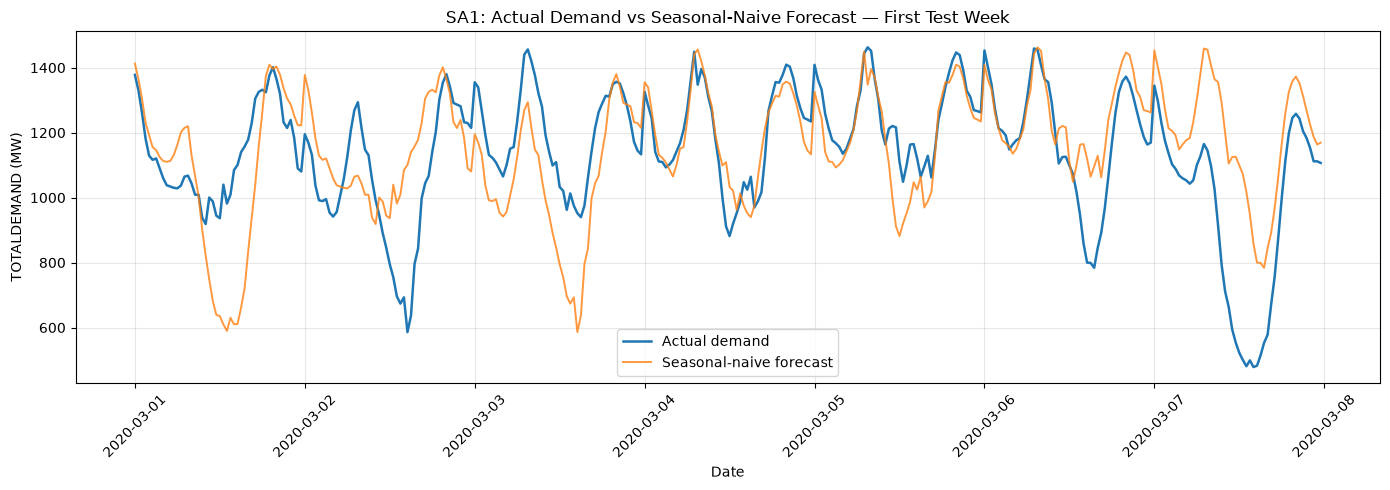

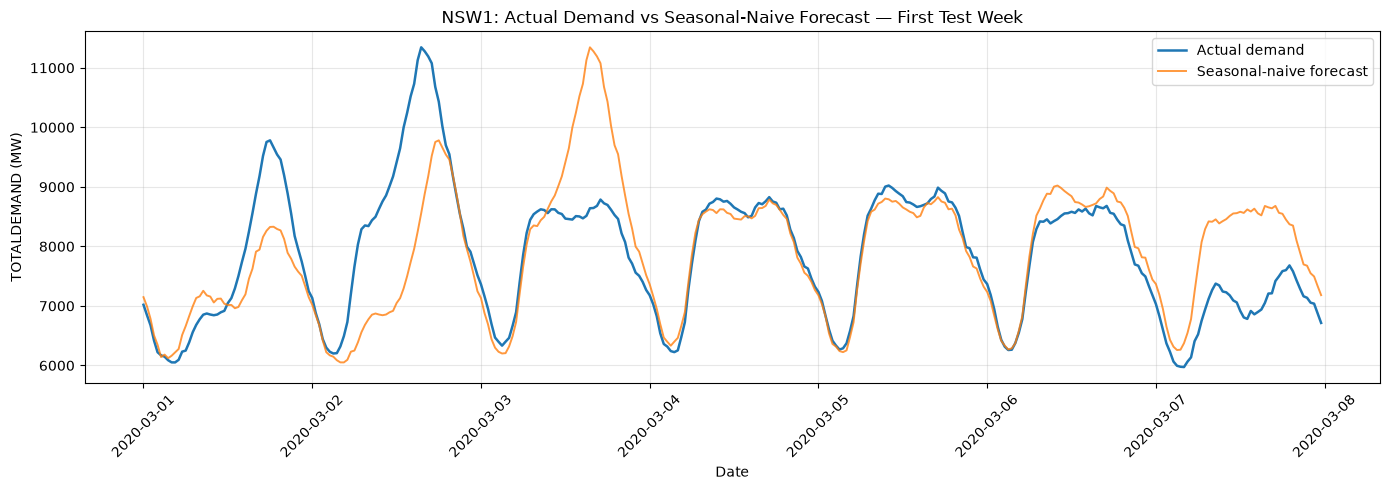

In [13]:
def plot_first_week(
    results,
    region_name
):
    first_week = results.head(48 * 7)

    plt.figure(figsize=(14, 5))

    plt.plot(
        first_week["SETTLEMENTDATE"],
        first_week["TOTALDEMAND"],
        label="Actual demand",
        linewidth=1.8
    )

    plt.plot(
        first_week["SETTLEMENTDATE"],
        first_week["prediction"],
        label="Seasonal-naive forecast",
        linewidth=1.4,
        alpha=0.8
    )

    plt.title(
        f"{region_name}: Actual Demand vs "
        "Seasonal-Naive Forecast — First Test Week"
    )

    plt.xlabel("Date")
    plt.ylabel("TOTALDEMAND (MW)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()


plot_first_week(
    sa1_results,
    "SA1"
)

plot_first_week(
    nsw1_results,
    "NSW1"
)

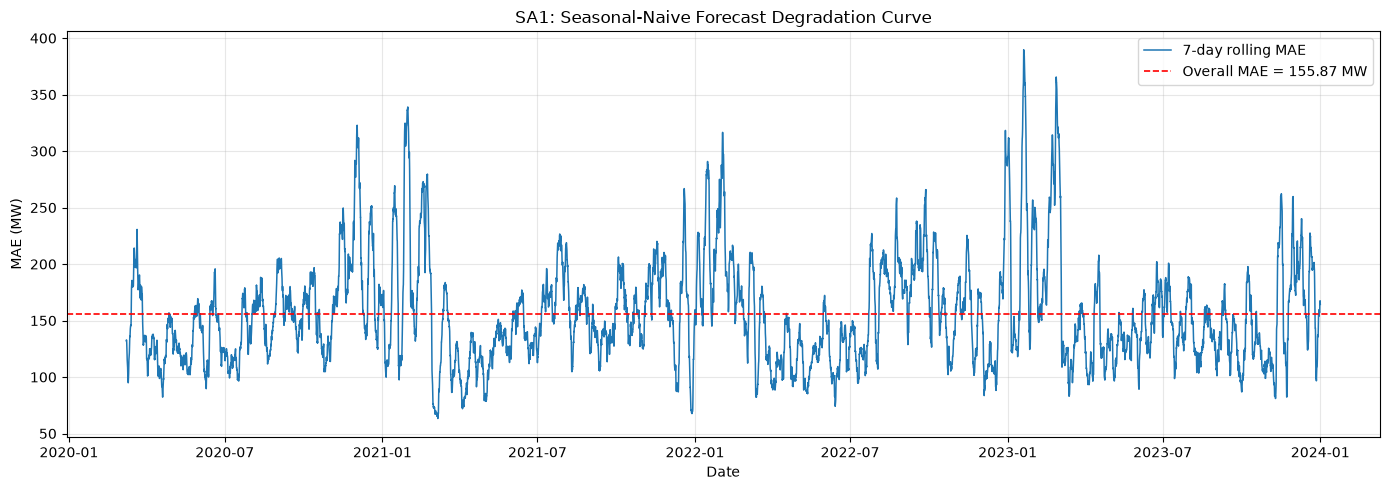

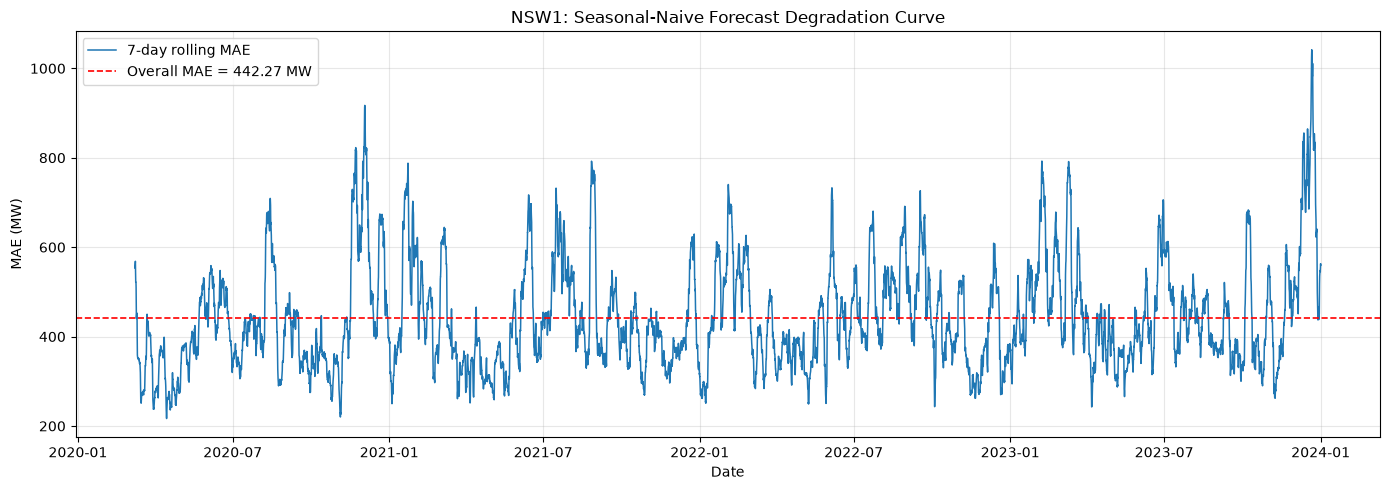

In [14]:
def plot_degradation_curve(
    results,
    overall_mae,
    region_name
):
    plt.figure(figsize=(14, 5))

    plt.plot(
        results["SETTLEMENTDATE"],
        results["rolling_mae_7d"],
        label="7-day rolling MAE",
        linewidth=1.1
    )

    plt.axhline(
        y=overall_mae,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label=f"Overall MAE = {overall_mae:.2f} MW"
    )

    plt.title(
        f"{region_name}: Seasonal-Naive "
        "Forecast Degradation Curve"
    )

    plt.xlabel("Date")
    plt.ylabel("MAE (MW)")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_degradation_curve(
    sa1_results,
    sa1_mae,
    "SA1"
)

plot_degradation_curve(
    nsw1_results,
    nsw1_mae,
    "NSW1"
)

In [15]:
import numpy as np


sa1_error_stream = (
    sa1_results["error"]
    .to_numpy()
)

nsw1_error_stream = (
    nsw1_results["error"]
    .to_numpy()
)


def validate_detector_stream(
    stream,
    region_name
):
    if stream.ndim != 1:
        raise ValueError(
            f"{region_name}: error stream is not one-dimensional."
        )

    if not np.issubdtype(
        stream.dtype,
        np.number
    ):
        raise ValueError(
            f"{region_name}: error stream is not numeric."
        )

    if not np.isfinite(stream).all():
        raise ValueError(
            f"{region_name}: error stream contains invalid values."
        )

    print(
        f"{region_name} detector stream is compatible."
    )
    print("Length:", len(stream))
    print("Dimensions:", stream.ndim)
    print("Data type:", stream.dtype)


validate_detector_stream(
    sa1_error_stream,
    "SA1"
)

validate_detector_stream(
    nsw1_error_stream,
    "NSW1"
)

SA1 detector stream is compatible.
Length: 67249
Dimensions: 1
Data type: float64
NSW1 detector stream is compatible.
Length: 67249
Dimensions: 1
Data type: float64


## Initial Findings

The frozen seasonal-naive baseline was evaluated on the fixed test stream from March 2020 to January 2024.

- SA1 achieved an overall MAE of **155.87 MW**.
- NSW1 achieved an overall MAE of **442.27 MW**.
- Both regions produced predictions for all **67,249** test observations.
- The 7-day rolling MAE curves vary substantially over time and contain several periods of elevated forecasting error.
- NSW1 shows larger absolute errors than SA1, partly reflecting its larger electricity-demand scale.

These changes in forecasting error indicate periods in which the fixed baseline performs less effectively. However, the degradation curves alone do not establish that concept drift has occurred. Formal drift detectors and event-based analysis are required before attributing these changes to concept drift.

The chronological error streams produced by this notebook are one-dimensional numeric arrays with no missing values and are compatible with the project's detector interface.